# 3D Jerk-Controlled Lattice Motion Primitives in JAX — Part 1: Primitives & GetSuccessors

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_lattice_primitives_3d_jerk_jax_colab.ipynb)

This tutorial is **Part 1** of a two-part minimal classroom series implementing **Liu et al. (2017)**, *"Search-based Motion Planning for Quadrotors using Linear Quadratic Minimum Time Control"* (`docs/lattice_quad.pdf`), in pure **JAX** for the **3D Jerk-Controlled System ($n = 3$, $M = 27$ motion primitives)**.

### Roadmap of Part 1
1. **Block 1 — Single 3D Constant-Jerk Motion Primitive (Section III-A)**: Exact linear time-invariant (LTI) transition matrices $F(t), G(t)$, trajectory evaluation $\mathbf{s}(t) \in \mathbb{R}^{3 \times 3}$, and Linear Quadratic Minimum Time (LQMT) edge cost $c(\mathbf{u}_m) = (\|\mathbf{u}_m\|_2^2 + \rho)\tau$.
2. **Block 2 — Discretized 3D Control Lattice $\mathcal{U}_{27}$ & `jax.vmap` Rollout (Sections III-A & III-B, Fig. 3b)**: Constructing the 3D control set $\mathcal{U}_{27} = \{-j_{\max}, 0, +j_{\max}\}^3$, rolling out all $M = 27$ primitives in parallel via `jax.vmap`, and verifying **Proposition 1 / Appendix A** (exact integer state-lattice quantization).
3. **Block 3 — Vectorized `get_successors` with Dynamic & Obstacle Pruning (Algorithm 1 & Section III-E)**: Checking componentwise velocity/acceleration limits ($\|\mathbf{v}(t)\|_\infty \leq v_{\max}$, $\|\mathbf{a}(t)\|_\infty \leq a_{\max}$), workspace bounds, and 3D obstacle clearance over dense intra-primitive time samples $t_i = \frac{i}{I}\tau$.


In [1]:
import subprocess, sys

for pkg in ("jax", "matplotlib"):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

jax.config.update("jax_default_matmul_precision", "highest")

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

print(f"JAX version : {jax.__version__}")
print(f"Backend     : {jax.default_backend()}")
print(f"Devices     : {jax.devices()}")


JAX version : 0.6.2


Backend     : gpu
Devices     : [CudaDevice(id=0)]


---
## Block 1: Single 3D Constant-Jerk Motion Primitive (Section III-A)

Liu et al. (2017) exploit differential flatness of the quadrotor in $(x, y, z)$ by modeling each translational axis as a **triple integrator ($n = 3$)** driven by constant jerk over duration $\tau > 0$.

### State and Control Representation
We stack the 3D position $\mathbf{p} \in \mathbb{R}^3$, velocity $\mathbf{v} \in \mathbb{R}^3$, and acceleration $\mathbf{a} \in \mathbb{R}^3$ as rows of a state matrix $\mathbf{s}(t) \in \mathbb{R}^{3 \times 3}$, and apply a constant 3D jerk vector $\mathbf{u}_m \in \mathbb{R}^3$ over $t \in [0, \tau]$:
$$\mathbf{s}(t) = \begin{bmatrix} \mathbf{p}(t)^\top \\ \mathbf{v}(t)^\top \\ \mathbf{a}(t)^\top \end{bmatrix} \in \mathbb{R}^{3 \times 3}, \qquad \dot{\mathbf{s}}(t) = A\mathbf{s}(t) + B\mathbf{u}_m^\top, \qquad A = \begin{bmatrix} 0 & 1 & 0 \\ 0 & 0 & 1 \\ 0 & 0 & 0 \end{bmatrix}, \quad B = \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix}$$

### Exact Closed-Form LTI Transition & LQMT Primitive Cost
Integrating the triple-integrator dynamics on $t \in [0, \tau]$ yields the exact matrix exponential $F(t) = e^{At}$ and forced response vector $G(t) = \int_0^t e^{A(t-\sigma)}B\,d\sigma$:
$$F(t) = e^{At} = \begin{bmatrix} 1 & t & \tfrac{1}{2}t^2 \\ 0 & 1 & t \\ 0 & 0 & 1 \end{bmatrix}, \qquad G(t) = \int_0^t e^{A(t-\sigma)}B\,d\sigma = \begin{bmatrix} \tfrac{1}{6}t^3 \\ \tfrac{1}{2}t^2 \\ t \end{bmatrix}, \qquad \mathbf{s}(t) = F(t)\mathbf{s}_0 + G(t)\mathbf{u}_m^\top$$

Under the **Linear Quadratic Minimum Time (LQMT)** objective $\mathcal{J} = \int_0^T (\|\mathbf{u}(t)\|_2^2 + \rho)\,dt$ with time weight $\rho > 0$, a single constant-jerk primitive over duration $\tau$ incurs the exact stage cost:
$$c(\mathbf{u}_m) = \left(\|\mathbf{u}_m\|_2^2 + \rho\right)\tau$$


Initial state s0 [p; v; a]:
 [[ 0.   0.   0. ]
 [ 1.   0.2  0. ]
 [ 0.   0.5 -0.2]]

Endpoint state s(tau) [p; v; a]:
 [[ 0.5417  0.1312 -0.0042]
 [ 1.25    0.2625  0.025 ]
 [ 1.     -0.25    0.3   ]]

Primitive LQMT cost c(u) = (||u||_2^2 + rho)*tau = 8.6250


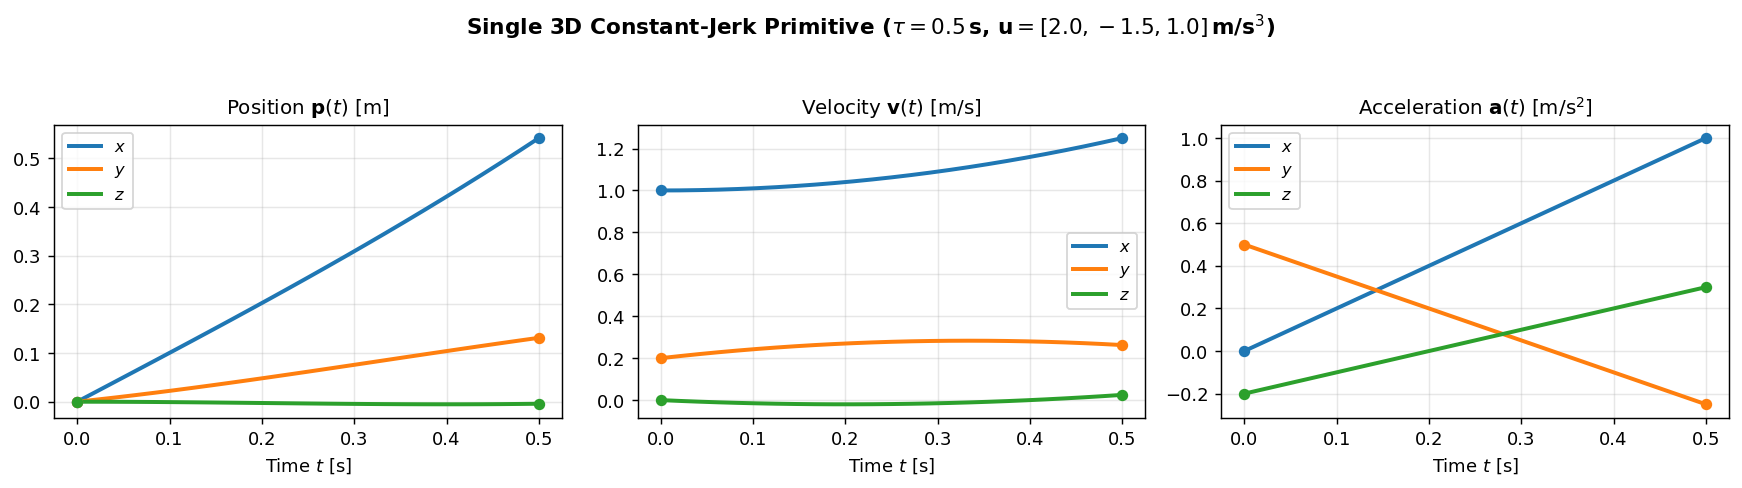

In [2]:
def F_mat(t):
    return jnp.array([
        [1.0, t, 0.5 * t**2],
        [0.0, 1.0, t],
        [0.0, 0.0, 1.0],
    ])


def G_vec(t):
    return jnp.array([
        (1.0 / 6.0) * t**3,
        0.5 * t**2,
        t,
    ])


def eval_primitive_step(s0, u, t):
    return F_mat(t) @ s0 + jnp.outer(G_vec(t), u)


def eval_primitive(s0, u, t_grid):
    return jax.vmap(eval_primitive_step, in_axes=(None, None, 0))(s0, u, t_grid)


def primitive_cost(u, tau, rho):
    return (jnp.dot(u, u) + rho) * tau


# Single 3D motion primitive demonstration
tau = 0.5
rho = 10.0
s0_demo = jnp.array([
    [0.0, 0.0, 0.0],   # p0 [m]
    [1.0, 0.2, 0.0],   # v0 [m/s]
    [0.0, 0.5, -0.2],  # a0 [m/s^2]
])
u_demo = jnp.array([2.0, -1.5, 1.0])  # constant 3D jerk [m/s^3]

t_grid = jnp.linspace(0.0, tau, 25)
traj_demo = eval_primitive(s0_demo, u_demo, t_grid)
s_end = traj_demo[-1]
cost_demo = primitive_cost(u_demo, tau, rho)

print("Initial state s0 [p; v; a]:\n", np.round(np.asarray(s0_demo), 4))
print("\nEndpoint state s(tau) [p; v; a]:\n", np.round(np.asarray(s_end), 4))
print(f"\nPrimitive LQMT cost c(u) = (||u||_2^2 + rho)*tau = {float(cost_demo):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
state_titles = [
    r"Position $\mathbf{p}(t)$ [m]",
    r"Velocity $\mathbf{v}(t)$ [m/s]",
    r"Acceleration $\mathbf{a}(t)$ [m/s$^2$]",
]
axis_labels = [r"$x$", r"$y$", r"$z$"]
axis_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for k in range(3):
    ax = axes[k]
    for d in range(3):
        ax.plot(t_grid, traj_demo[:, k, d], color=axis_colors[d], lw=2.2, label=axis_labels[d])
        ax.scatter(
            [0.0, tau],
            [traj_demo[0, k, d], traj_demo[-1, k, d]],
            color=axis_colors[d],
            s=28,
            zorder=4,
        )
    ax.set_title(state_titles[k])
    ax.set_xlabel(r"Time $t$ [s]")
    ax.legend(loc="best", frameon=True)

fig.suptitle(
    r"Single 3D Constant-Jerk Primitive ($\tau = 0.5\,$s, $\mathbf{u} = [2.0, -1.5, 1.0]\,$m/s$^3$)",
    y=1.03,
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


---
## Block 2: Discretized 3D Control Lattice $\mathcal{U}_{27}$ & `jax.vmap` Rollout (Sections III-A & III-B, Fig. 3b)

To build a finite branching factor for graph search, each component of $\mathbf{u}_m \in [-j_{\max}, j_{\max}]^3$ is discretized uniformly with integer resolution $\mu \in \mathbb{Z}^+$:
$$u_{m,d} \in \left\{-\mu\,\delta u,\; (-\mu+1)\,\delta u,\; \dots,\; \mu\,\delta u\right\}, \qquad \delta u = \frac{j_{\max}}{\mu}$$
For $\mu = 1$ in 3D, each axis takes values in $\{-j_{\max}, 0, +j_{\max}\}$, yielding $M = (2\mu + 1)^3 = 3^3 = 27$ motion primitives $\mathcal{U}_{27} \subset \mathbb{R}^3$.

### Proposition 1 & Appendix A: Induced State-Lattice Quantization
Applying constant controls from $\mathcal{U}_M$ over fixed duration $\tau$ maps any lattice-aligned state $\mathbf{s}_0$ strictly onto a discrete regular lattice in position, velocity, and acceleration with quantization units:
$$\Delta p = \frac{\delta u\,\tau^3}{6}, \qquad \Delta v = \frac{\delta u\,\tau^2}{2}, \qquad \Delta a = \delta u\,\tau$$
Notice that $\Delta v\,\tau = 3\,\Delta p$ and $\frac{1}{2}\Delta a\,\tau^2 = 3\,\Delta p$. Consequently, if $\mathbf{p}_0/\Delta p \in \mathbb{Z}^3$, $\mathbf{v}_0/\Delta v \in \mathbb{Z}^3$, and $\mathbf{a}_0/\Delta a \in \mathbb{Z}^3$, then for every $\mathbf{u}_m \in \mathcal{U}_{27}$:
$$\frac{\mathbf{p}(\tau)}{\Delta p} = \frac{\mathbf{p}_0}{\Delta p} + 3\frac{\mathbf{v}_0}{\Delta v} + 3\frac{\mathbf{a}_0}{\Delta a} + \frac{\mathbf{u}_m}{\delta u} \in \mathbb{Z}^3, \qquad \frac{\mathbf{v}(\tau)}{\Delta v} = \frac{\mathbf{v}_0}{\Delta v} + 2\frac{\mathbf{a}_0}{\Delta a} + \frac{\mathbf{u}_m}{\delta u} \in \mathbb{Z}^3, \qquad \frac{\mathbf{a}(\tau)}{\Delta a} = \frac{\mathbf{a}_0}{\Delta a} + \frac{\mathbf{u}_m}{\delta u} \in \mathbb{Z}^3$$


Control lattice U_M shape         : (27, 3)
Rollout batch shape               : (27, 25, 3, 3)
Lattice units (dp, dv, da)        : (0.041667 m, 0.2500 m/s, 1.0000 m/s^2)
Max integer lattice rounding error: 1.19e-07


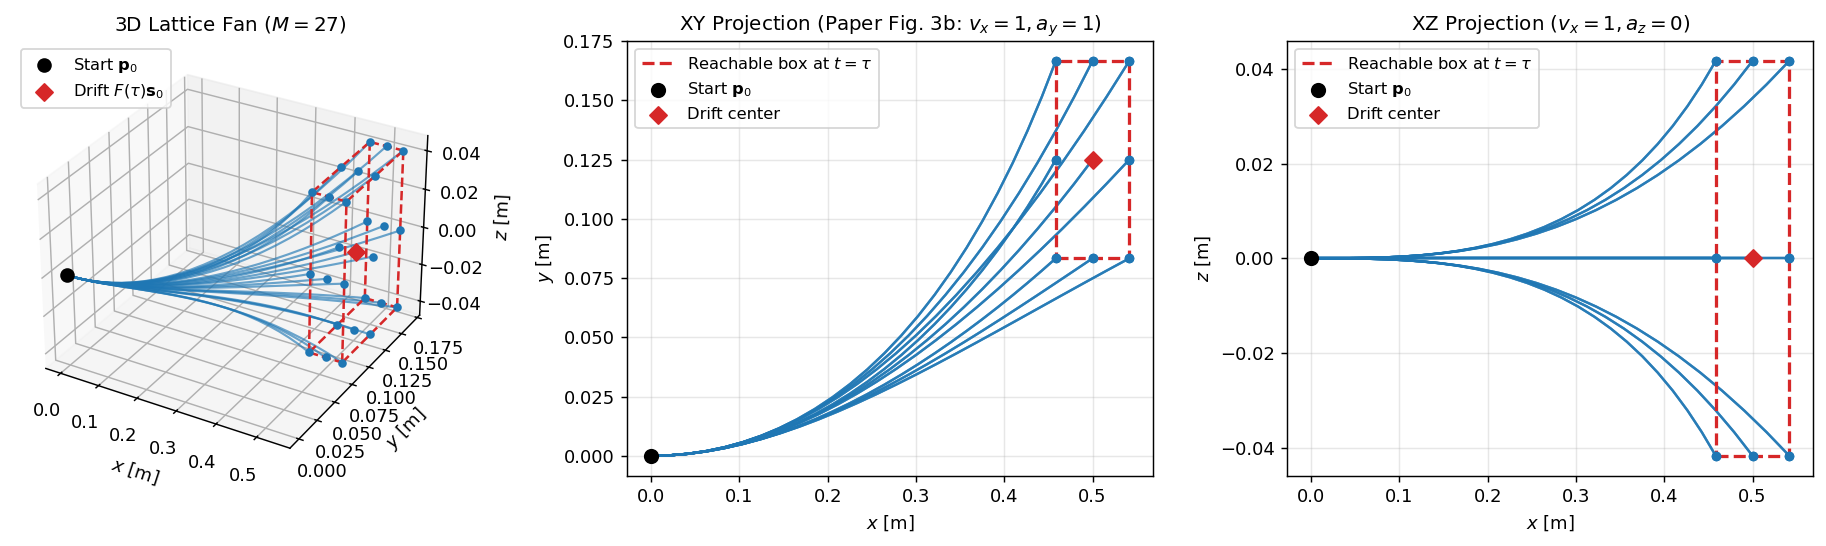

In [3]:
j_max = 2.0
tau = 0.5
rho = 10.0

# Build U_M of shape (27, 3) with u_d in {-j_max, 0, +j_max}
u_axis = jnp.array([-j_max, 0.0, j_max])
ugx, ugy, ugz = jnp.meshgrid(u_axis, u_axis, u_axis, indexing="ij")
U_M = jnp.stack([ugx.ravel(), ugy.ravel(), ugz.ravel()], axis=-1)  # (27, 3)

# Vectorize primitive rollout and cost across all M = 27 controls
eval_primitives_batch = jax.vmap(eval_primitive, in_axes=(None, 0, None))
primitive_costs_batch = jax.vmap(primitive_cost, in_axes=(0, None, None))

# Initial state matching Fig. 3b of Liu et al. (2017): p0=[0,0,0], v0=[1,0,0], a0=[0,1,0]
s0_fig3b = jnp.array([
    [0.0, 0.0, 0.0],
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0],
])

trajs_27 = eval_primitives_batch(s0_fig3b, U_M, t_grid)  # (27, T, 3, 3)
s_next_27 = trajs_27[:, -1, :, :]                        # (27, 3, 3)

# Verify Proposition 1 / Appendix A integer lattice quantization
dp = j_max * (tau**3) / 6.0
dv = j_max * (tau**2) / 2.0
da = j_max * tau
quant_units = jnp.array([dp, dv, da])[:, None]           # (3, 1)

lattice_coords = s_next_27 / quant_units
quant_err = jnp.max(jnp.abs(lattice_coords - jnp.round(lattice_coords)))

print(f"Control lattice U_M shape         : {U_M.shape}")
print(f"Rollout batch shape               : {trajs_27.shape}")
print(f"Lattice units (dp, dv, da)        : ({dp:.6f} m, {dv:.4f} m/s, {da:.4f} m/s^2)")
print(f"Max integer lattice rounding error: {float(quant_err):.2e}")

# Zero-input drift endpoint and reachable position box [p_drift - dp, p_drift + dp]^3
p_drift = (F_mat(tau) @ s0_fig3b)[0]

fig = plt.figure(figsize=(14.5, 4.3))
ax3d = fig.add_subplot(1, 3, 1, projection="3d")
ax_xy = fig.add_subplot(1, 3, 2)
ax_xz = fig.add_subplot(1, 3, 3)

for m in range(U_M.shape[0]):
    px, py, pz = trajs_27[m, :, 0, 0], trajs_27[m, :, 0, 1], trajs_27[m, :, 0, 2]
    ax3d.plot(px, py, pz, color="#1f77b4", alpha=0.65, lw=1.2)
    ax3d.scatter(px[-1], py[-1], pz[-1], color="#1f77b4", s=14)
    ax_xy.plot(px, py, color="#1f77b4", alpha=0.65, lw=1.3)
    ax_xy.scatter(px[-1], py[-1], color="#1f77b4", s=18, zorder=3)
    ax_xz.plot(px, pz, color="#1f77b4", alpha=0.65, lw=1.3)
    ax_xz.scatter(px[-1], pz[-1], color="#1f77b4", s=18, zorder=3)

# Draw 3D reachable box edges at t = tau
b_min = np.asarray(p_drift - dp)
b_max = np.asarray(p_drift + dp)
corners = np.array([[x, y, z] for x in (b_min[0], b_max[0]) for y in (b_min[1], b_max[1]) for z in (b_min[2], b_max[2])])
for i in range(8):
    for j in range(i + 1, 8):
        if np.sum(np.abs(corners[i] - corners[j]) > 1e-7) == 1:
            ax3d.plot(
                [corners[i, 0], corners[j, 0]],
                [corners[i, 1], corners[j, 1]],
                [corners[i, 2], corners[j, 2]],
                color="#d62728",
                lw=1.4,
                ls="--",
            )

ax3d.scatter([0.0], [0.0], [0.0], color="black", s=50, label=r"Start $\mathbf{p}_0$")
ax3d.scatter([p_drift[0]], [p_drift[1]], [p_drift[2]], color="#d62728", s=45, marker="D", label=r"Drift $F(\tau)\mathbf{s}_0$")
ax3d.set_title(r"3D Lattice Fan ($M = 27$)")
ax3d.set_xlabel(r"$x$ [m]")
ax3d.set_ylabel(r"$y$ [m]")
ax3d.set_zlabel(r"$z$ [m]", labelpad=6)
ax3d.legend(loc="upper left")

for ax, d1, d2, lbl1, lbl2, title in [
    (ax_xy, 0, 1, r"$x$ [m]", r"$y$ [m]", r"XY Projection (Paper Fig. 3b: $v_x=1, a_y=1$)"),
    (ax_xz, 0, 2, r"$x$ [m]", r"$z$ [m]", r"XZ Projection ($v_x=1, a_z=0$)"),
]:
    rect_x = [b_min[d1], b_max[d1], b_max[d1], b_min[d1], b_min[d1]]
    rect_y = [b_min[d2], b_min[d2], b_max[d2], b_max[d2], b_min[d2]]
    ax.plot(rect_x, rect_y, color="#d62728", lw=1.8, ls="--", label=r"Reachable box at $t=\tau$")
    ax.scatter([0.0], [0.0], color="black", s=55, zorder=5, label=r"Start $\mathbf{p}_0$")
    ax.scatter([p_drift[d1]], [p_drift[d2]], color="#d62728", s=45, marker="D", zorder=5, label=r"Drift center")
    ax.set_title(title)
    ax.set_xlabel(lbl1)
    ax.set_ylabel(lbl2)
    ax.legend(loc="upper left", frameon=True)

plt.tight_layout(w_pad=2.2)
plt.show()


---
## Block 3: Vectorized `get_successors` with Dynamic & Obstacle Pruning (Algorithm 1 & Section III-E)

During graph search, **Algorithm 1 (`GetSuccessors`)** expands a parent lattice state $\mathbf{s} \in \mathbb{R}^{3 \times 3}$ across all $M = 27$ controls $\mathbf{u}_m \in \mathcal{U}_{27}$ and prunes any primitive that violates dynamic or collision constraints at $I$ dense intermediate sample times $t_i = \frac{i}{I}\tau$ ($i = 0, \dots, I$):

1. **Componentwise Velocity & Acceleration Limits (Section III-E)**:
   $$\|\mathbf{v}(t_i)\|_\infty \leq v_{\max}, \qquad \|\mathbf{a}(t_i)\|_\infty \leq a_{\max} \qquad \forall\, i \in \{0, \dots, I\}$$
2. **Workspace Bounding Box & 3D Obstacle Clearance**:
   $$\mathbf{p}_{\min} \leq \mathbf{p}(t_i) \leq \mathbf{p}_{\max}, \qquad \|\mathbf{p}(t_i) - \mathbf{c}_{\text{obs}}\|_2 > r_{\text{obs}} \qquad \forall\, i \in \{0, \dots, I\}$$

In JAX, all 27 primitives and all $I + 1$ sample points are checked simultaneously without Python loops, returning a boolean `valid_mask` alongside the successor states `s_next` and LQMT edge costs `edge_costs`.


Total primitives evaluated        : 27
Valid successor primitives        : 8
Pruned by velocity/accel limits   : 15 (vel violations: 9, acc violations: 9)
Pruned by 3D obstacle collision   : 4


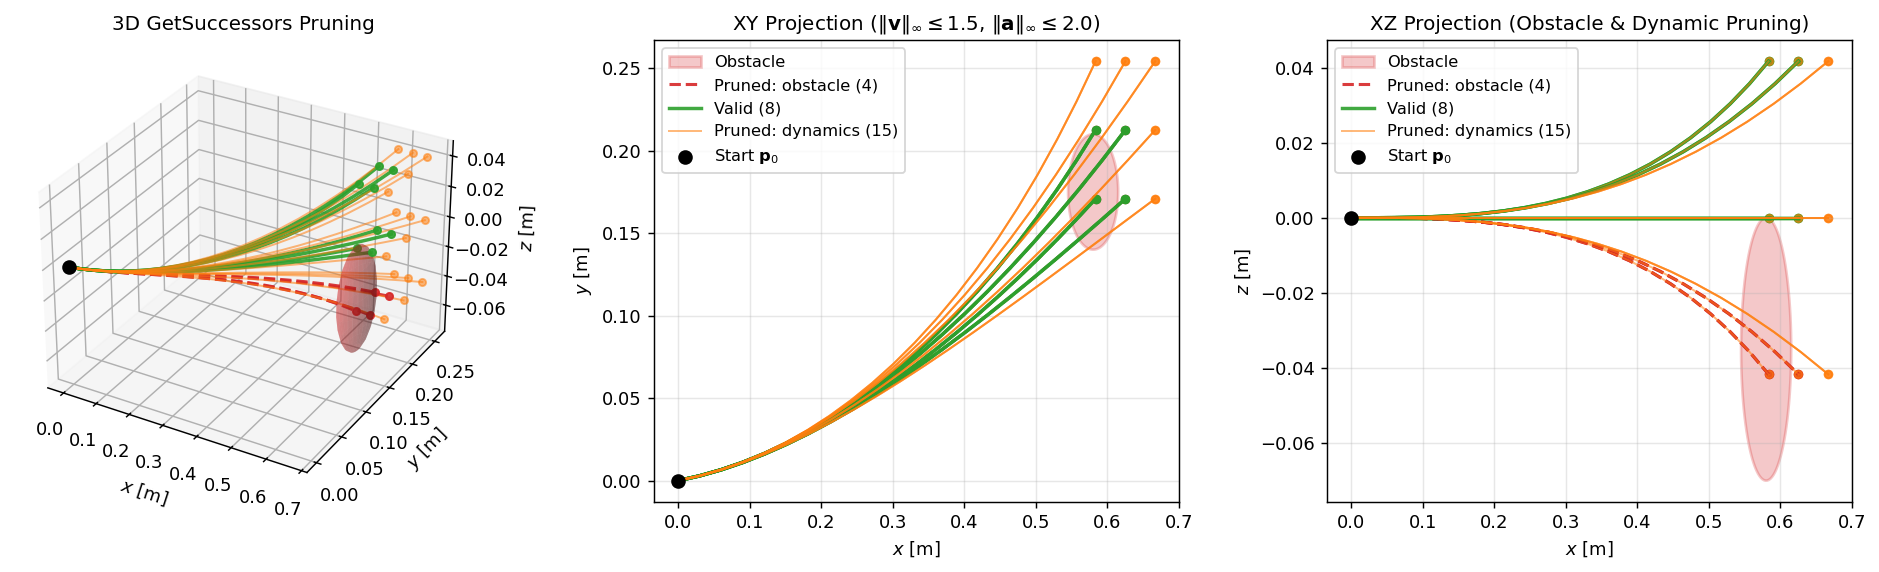

In [4]:
v_max = 1.5
a_max = 2.0
p_min = jnp.array([-2.0, -2.0, -2.0])
p_max = jnp.array([2.0, 2.0, 2.0])
obs_center = jnp.array([0.58, 0.175, -0.035])
obs_radius = 0.035

t_check = jnp.linspace(0.0, tau, 21)
EDGE_COSTS_27 = primitive_costs_batch(U_M, tau, rho)


@jax.jit
def get_successors(s):
    trajs = eval_primitives_batch(s, U_M, t_check)  # (27, I+1, 3, 3)
    pos = trajs[:, :, 0, :]                         # (27, I+1, 3)
    vel = trajs[:, :, 1, :]                         # (27, I+1, 3)
    acc = trajs[:, :, 2, :]                         # (27, I+1, 3)

    vel_ok = jnp.all(jnp.abs(vel) <= v_max, axis=(1, 2))
    acc_ok = jnp.all(jnp.abs(acc) <= a_max, axis=(1, 2))
    box_ok = jnp.all((pos >= p_min) & (pos <= p_max), axis=(1, 2))
    obs_ok = jnp.all(jnp.linalg.norm(pos - obs_center, axis=-1) > obs_radius, axis=1)

    valid_mask = vel_ok & acc_ok & box_ok & obs_ok
    s_next = trajs[:, -1, :, :]
    return s_next, valid_mask, EDGE_COSTS_27, trajs, vel_ok, acc_ok, obs_ok


# Test from a moving state near dynamic limits and approaching the 3D obstacle
s_query = jnp.array([
    [0.0, 0.0, 0.0],   # p0 [m]
    [1.2, 0.1, 0.0],   # v0 [m/s] (near v_max = 1.5 along +x)
    [0.2, 1.3, 0.0],   # a0 [m/s^2] (near a_max = 2.0 along +y)
])

s_next, valid_mask, edge_costs, trajs, vel_ok, acc_ok, obs_ok = get_successors(s_query)
dyn_ok = vel_ok & acc_ok
pruned_dyn = ~dyn_ok
pruned_obs = dyn_ok & (~obs_ok)

print(f"Total primitives evaluated        : {U_M.shape[0]}")
print(f"Valid successor primitives        : {int(jnp.sum(valid_mask))}")
print(f"Pruned by velocity/accel limits   : {int(jnp.sum(pruned_dyn))} "
      f"(vel violations: {int(jnp.sum(~vel_ok))}, acc violations: {int(jnp.sum(~acc_ok))})")
print(f"Pruned by 3D obstacle collision   : {int(jnp.sum(pruned_obs))}")

fig = plt.figure(figsize=(14.8, 4.5))
ax3d = fig.add_subplot(1, 3, 1, projection="3d")
ax_xy = fig.add_subplot(1, 3, 2)
ax_xz = fig.add_subplot(1, 3, 3)

# Render 3D sphere wireframe for the obstacle
u_sph, v_sph = np.mgrid[0:2 * np.pi:24j, 0:np.pi:12j]
xs = obs_center[0] + obs_radius * np.cos(u_sph) * np.sin(v_sph)
ys = obs_center[1] + obs_radius * np.sin(u_sph) * np.sin(v_sph)
zs = obs_center[2] + obs_radius * np.cos(v_sph)
ax3d.plot_surface(xs, ys, zs, color="#d62728", alpha=0.32, edgecolor="none")

theta = np.linspace(0.0, 2.0 * np.pi, 100)
ax_xy.fill(
    obs_center[0] + obs_radius * np.cos(theta),
    obs_center[1] + obs_radius * np.sin(theta),
    color="#d62728",
    alpha=0.25,
    edgecolor="#d62728",
    lw=1.5,
    label="Obstacle",
)
ax_xz.fill(
    obs_center[0] + obs_radius * np.cos(theta),
    obs_center[2] + obs_radius * np.sin(theta),
    color="#d62728",
    alpha=0.25,
    edgecolor="#d62728",
    lw=1.5,
    label="Obstacle",
)

added_labels = {"valid": False, "dyn": False, "obs": False}
for m in range(U_M.shape[0]):
    px, py, pz = trajs[m, :, 0, 0], trajs[m, :, 0, 1], trajs[m, :, 0, 2]
    if bool(valid_mask[m]):
        col, ls, lw, alpha, key, lbl = (
            "#2ca02c", "-", 1.9, 0.9, "valid",
            f"Valid ({int(jnp.sum(valid_mask))})"
        )
    elif bool(pruned_dyn[m]):
        col, ls, lw, alpha, key, lbl = (
            "#ff7f0e", "-", 1.1, 0.55, "dyn",
            f"Pruned: dynamics ({int(jnp.sum(pruned_dyn))})"
        )
    else:
        col, ls, lw, alpha, key, lbl = (
            "#d62728", "--", 1.7, 0.9, "obs",
            f"Pruned: obstacle ({int(jnp.sum(pruned_obs))})"
        )

    plot_lbl = lbl if not added_labels[key] else None
    added_labels[key] = True

    ax3d.plot(px, py, pz, color=col, ls=ls, lw=lw, alpha=alpha)
    ax3d.scatter(px[-1], py[-1], pz[-1], color=col, s=16, alpha=alpha)
    ax_xy.plot(px, py, color=col, ls=ls, lw=lw, alpha=alpha, label=plot_lbl)
    ax_xy.scatter(px[-1], py[-1], color=col, s=18, alpha=alpha)
    ax_xz.plot(px, pz, color=col, ls=ls, lw=lw, alpha=alpha, label=plot_lbl)
    ax_xz.scatter(px[-1], pz[-1], color=col, s=18, alpha=alpha)

ax3d.scatter([0.0], [0.0], [0.0], color="black", s=50, label=r"Start $\mathbf{p}_0$")
ax3d.set_title("3D GetSuccessors Pruning")
ax3d.set_xlabel(r"$x$ [m]")
ax3d.set_ylabel(r"$y$ [m]")
ax3d.set_zlabel(r"$z$ [m]", labelpad=6)

ax_xy.scatter([0.0], [0.0], color="black", s=50, zorder=5, label=r"Start $\mathbf{p}_0$")
ax_xy.set_title(r"XY Projection ($\|\mathbf{v}\|_\infty \leq 1.5$, $\|\mathbf{a}\|_\infty \leq 2.0$)")
ax_xy.set_xlabel(r"$x$ [m]")
ax_xy.set_ylabel(r"$y$ [m]")
ax_xy.legend(loc="upper left", frameon=True)

ax_xz.scatter([0.0], [0.0], color="black", s=50, zorder=5, label=r"Start $\mathbf{p}_0$")
ax_xz.set_title(r"XZ Projection (Obstacle & Dynamic Pruning)")
ax_xz.set_xlabel(r"$x$ [m]")
ax_xz.set_ylabel(r"$z$ [m]")
ax_xz.legend(loc="upper left", frameon=True)

plt.tight_layout(w_pad=2.2)
plt.show()
